# Connectome Spectrum Transform from a template

If the patient's tractography is unavailable, you can infer a structural connectome using a connectome atlas. In this project, we use the MultiConn atlas from [Alemán-Gómez et. al 2022](https://www.nature.com/articles/s41597-022-01624-8).

The connectome in this context represents the structural connections between sources in our source space. These include white matter tracts (long-range connections) inferred from an atlas, and gray matter tracts (short-range connections) inferred from a specific method.

- **White Matter Tracts**: Two sources are connected if the brain regions they belong to are connected according to the MultiConn atlas. This requires segmenting the subject's brain using MultiConn's parcellation, which was done in `./parcellation.ipynb`. The parcellation results are stored in `../dataset/spike_sample/derivatives/mindmap/subject/parc/`.
- **Gray Matter Tracts**: Two sources are connected if their geodesic distance is smaller than a user-defined threshold.

Once the connectome for the source space is obtained, the Connectome Spectrum Transform is performed by computing the graph signal transform of the connectome.

# Batch Wise Run

Run the code for all subjects of a given dataset.

## 📦 Imports

In [1]:
import mindmap as mm
from pathlib import Path
import numpy as np

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `parc`: Parcellation
- `src`: Source space (after forward solution)
- `conn`: Connectome atlas

🛠️ <font color=violet>**Configuration**</font>:
- `fconfig`: Configuration file.


🛠️ <font color=violet>**Atlas (white matter tracts)**</font>:
- `consistency_thr`: Consistency threshold (number of people having connection out of 60 subjects)
- `length_thr`: Fiber length threshold in [mm]
- `number_thr`: Number of fiber threshold 

🛠️ <font color=violet>**Gray matter tracts**</font>:
- `distance_thr`: Maximum distance to connect two dipoles in [m]

🛠️ <font color=violet>**Other options**</font>:
- `overwrite`: Whether to overwrite existing files.

In [2]:
###################### Parameters #######################
# configuration
fconfig = "../configurations/spike.yml"

# atlas
consistency_thr = 40
length_thr = 25
number_thr = 20

# gm tracts
distance_thr = 0.010

# other options
overwrite = True
########################################################## 

# configuration
config   = mm.io.read_config(fconfig)
subjects = config["SUBS"]
mm_dir   = Path(config["MM_DIR"])

# file naming
fsc  = lambda sub: mm_dir/sub/"sc"/f"{sub}_sc-template.npy"
fcst = lambda sub: mm_dir/sub/"sc"/f"{sub}_cst.npy"

FileNotFoundError: [Errno 2] No such file or directory: '../configurations/spike.yml'

## ♾️ Loop

In [ ]:
for sub in subjects:
    # check file existence 
    sc_fname  = fsc(sub)
    cst_fname = fcst(sub)

    if cst_fname.exists() and not overwrite:
        print(f"\033[93mConnectome spectrum transform already exists for subject {sub}\033[0m")
        continue
    elif not cst_fname.parent.exists():
        cst_fname.parent.mkdir(parents=True)
    
    try:
        # Generate CST
        cst, sc = mm.utils.create_cst_from_template(sub, consistency_thr, length_thr, number_thr, distance_thr)
    except Exception as e:
        print(f"\033[91mFailed to generate CST for subject {sub} due to: {e}\033[0m")
        continue

    # save
    np.save(sc_fname, sc.todense())
    np.save(cst_fname, cst)

    print(f"\033[92mSuccessfully computed CST for subject '{sub}'\033[0m")

# Step Wise Run

Run the code step by step for a single subject.

## 📦 Imports

In [2]:
from pathlib import Path
import os

import mindmap as mm

import numpy as np
import scipy as sp
import pandas as pd
import pygsp

import matplotlib.pyplot as plt 

## 🧠 Data

In [4]:
################## Parameters ####################
# configuration
fconfig = "../../papers/simf/configuration.yml"
sub     = 1
##################################################

reader = mm.io.dataset_reader(fconfig)
mm_dir = reader.config["MM_DIR"]

data = reader(sub, "src", "parc", "white", "cras")
std  = reader.standards("conn")

DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- white
- src
- cras
- parc
Missing objects:
DATA SUMMARY
Dataset: simf
Subject: Standards
Retrieved objects:
- conn
Missing objects:


In [5]:


# parameters
cons_thresh = 40       # consistency threshold
len_thresh  = 25       # fiber length threshold
n_thresh    = 20       # number of streamlines threshold
dmax        = 0.010    # maximum distance for short distance connection

#### Additional utility

In [6]:
def correct_labels(labels, sources, parcel):
    """
    Correct labels that misplace left and right hemisphere dipoles because the parcellation is not perfect.
    """
    # map to switch from label id to label name
    clut = parcel.get_clut()
    map  = pd.Series(clut["Label name"].values, index=clut["#No."]).to_dict()
    
    label_names = [map[id] for id in labels]

    # left/right hemisphere seperation
    split = len(sources[0]["vertno"])

    # switch 'lh' labels in right hemisphere to 'rh' homologue and vice virsa
    label_names[:split] = [l.replace("-rh-", "-lh-") for l in label_names[:split]]
    label_names[split:] = [l.replace("-lh-", "-rh-") for l in label_names[split:]]

    # convert back to lable ids
    new_labels = [list(map.keys())[list(map.values()).index(n)] for n in label_names]

    return new_labels

## Infere Subject Connectome from Atlas Connectome
#### ⚙️ **<font color=green>Preprocess Atlas</font>**
First we threshold the atlas to our liking. Threshold values were chosen to produce the cleanest harmonics. <br>

🛠️ **<font color=violet>Thresholds</font>**:

- `cons_thresh`: Consistency threshold. Number of subjects that have the connection over total number of subjects (60).
- `len_thresh`: Fiber length threshold.
- `n_thresh`: Number of fibers threshold.

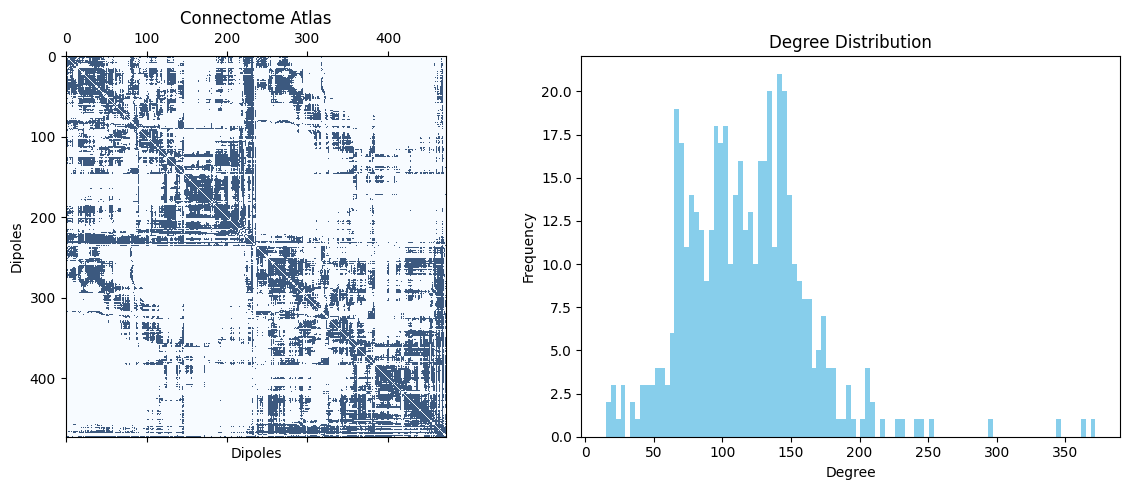

In [7]:
################## Parameters #################
# thresholds
cons_thresh = 40 
len_thresh  = 25  
n_thresh    = 20   
###############################################

# label sources
pos    = mm.utils.get_src_position(data["src"])
pos    = pos*1000 + data["cras"]                   # in surface RAS space in [mm].  !!!!!!! Add the cras translation now that I now  !!!!!!!
labels = data["parc"].label_points(pos, id=True)   # brain region label for each source.

# some left/right regions are very close and get mixed up
labels = mm.utils.correct_labels(labels, data["src"], data["parc"])

# convert atlas to binary adjacency matrix
consistency = std["conn"]["matrices"]["consistency"]
length      = std["conn"]["matrices"]["length"]
number      = std["conn"]["matrices"]["numbStlines"]

sc_atlas = np.bitwise_and(
    consistency[:,:] > cons_thresh, 
    length[:,:] > len_thresh,
    number[:,:] > n_thresh,
)

mm.viz.plot_connectome(sc_atlas, name="Connectome Atlas")

⚙️ <font color=green>**Infer White Matter Tracks from Atlas**</font>: Create connections between sources as follows: let $i$ be a source in region A and $j$ be a source in region B. If the atlas indicates that region A is connected to region B, then connect $i$ to $j$.

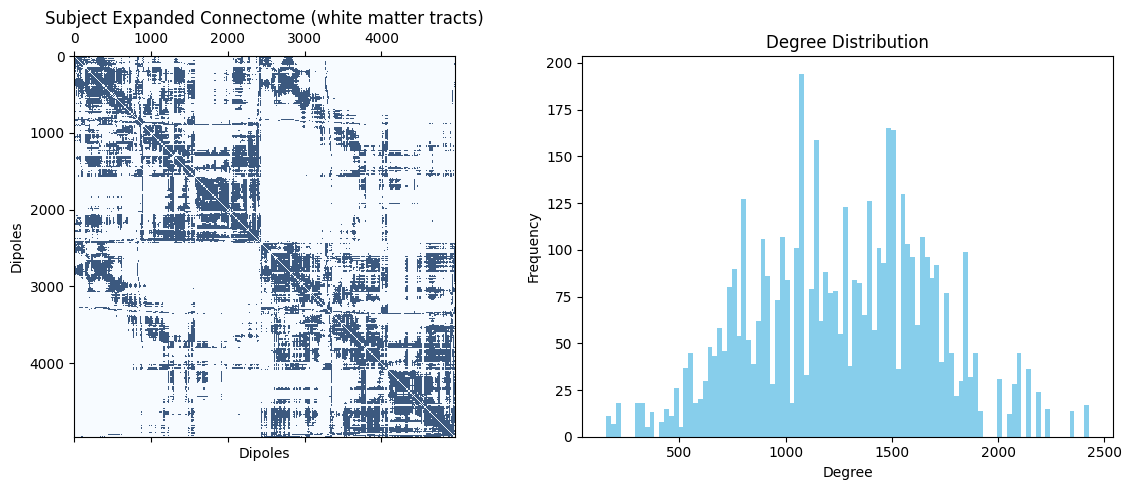

In [8]:
N = pos.shape[0]
sc = np.zeros((N,N))

for i, l in enumerate(labels):
    connected_regions = np.argwhere(sc_atlas[l-1]==1)+1
    connections = np.isin(labels, connected_regions)
    sc[i] = connections 

sc = sp.sparse.csc_array(sc>0)

# sort for plotting
idx = np.argsort(labels)
viz = sc.todense()[idx]
viz = viz[:,idx]
mm.viz.plot_connectome(viz, name="Subject Expanded Connectome (white matter tracts)")

⚙️ <font color=green>**Infer Gray Matter Tracks from Distance**</font>: If sources $i$ and $j$ are less than dmax distance apart, then connect $i$ and $j$.

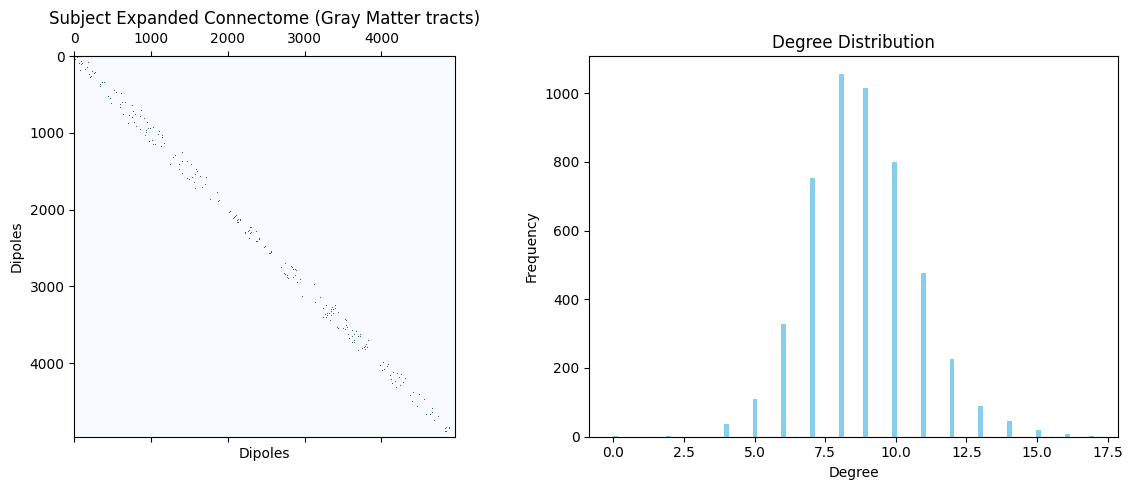

In [9]:
gmt = mm.utils.interpol_gm_tracks(data["src"], dmax)
mm.viz.plot_connectome(gmt.todense(), "Subject Expanded Connectome (Gray Matter tracts)")

⚙️ <font color=green>**Combine White Matter Tracks and Gray Matter Tracks**</font>

In [10]:
sc = sc + gmt 
sc = sc.astype(bool).astype(int)

#### <font color=yellow>🌟</font> Visualize Final Connectome

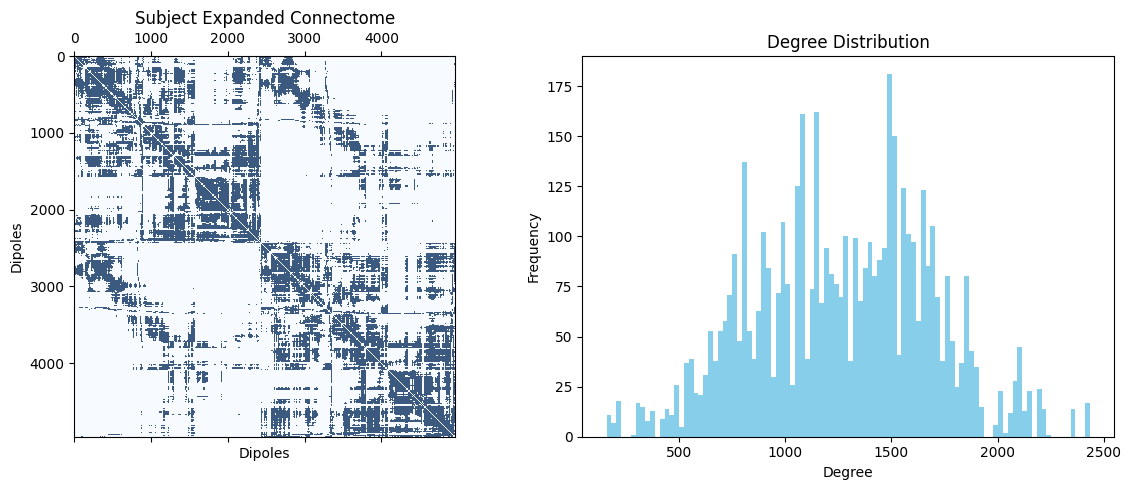

In [11]:
idx = np.argsort(labels)
viz = sc.todense()[idx]
viz = viz[:,idx]
mm.viz.plot_connectome(viz, "Subject Expanded Connectome")

## Connectome Spectrum Transform

⚙️ <font color=green>**Compute the Connectome Spectrum Transform (CST)**</font>: The CST is simply the Fourier Graph Transform of the connectome. The harmonics (or eigenvectors) of this transform are characteristic of the connectome. Visualize them to assess the quality of the CST.

In [12]:
coords = [s["rr"][s["vertno"]] for s in data["src"]]
G = pygsp.graphs.Graph(sc.todense(), lap_type="normalized", coords=coords)
G.compute_fourier_basis()
cst = G.U.T

2025-06-17 08:28:16,167:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (4961 x 4961) may take some time.


#### <font color=yellow>🌟</font> Visualize the harmonics

In [13]:
mm.viz.plot_harmonics(data["src"], cst).show()

Widget(value='<iframe src="http://localhost:34841/index.html?ui=P_0x79234d47f7d0_0&reconnect=auto" class="pyvi…

## 💾 Save the SC
🚨 The structural connectome (SC) is not needed for source reconstruction. Save only if needed for personal use.

In [19]:
folder = mm_dir/data["sub"]/"sc"
if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving SC from template for subject: {data['sub']}")
np.save(folder/f"{data['sub']}_sc-template.npy", sc.todense())

Saving SC from template for subject: vepcon_sub-10


## 💾 Save the CST

In [20]:
folder = mm_dir/data["sub"]/"sc"
if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving CST from template for subject: {data['sub']}")
np.save(folder/f"{data['sub']}_cst-template.npy", cst)

Saving CST from template for subject: vepcon_sub-10
